# WeLoveReviews — Análisis de Sentimiento en Reseñas de Clientes

## Objetivos del Proyecto

**WeLoveReviews** es una plataforma que agrega reseñas de clientes para negocios de servicios (restaurantes, cafeterías, etc.). Actualmente reportan un **rating promedio de aproximadamente 4.5/5 estrellas**, lo que sugiere una alta satisfacción general.

**Pregunta de negocio:** ¿El sentimiento expresado en el texto de las reseñas realmente coincide con esa puntuación? ¿O existen matices que la calificación numérica no captura?

Para responder esto, utilizaremos un modelo de análisis de sentimiento basado en BERT multilingüe (`nlptown/bert-base-multilingual-uncased-sentiment`) que clasifica reseñas en un rango de 1 a 5 estrellas, permitiendo una comparación directa con el rating humano.

## Estructura del análisis

1. **EDA** — Exploración y limpieza de los datos
2. **Modelo** — Carga y justificación del modelo elegido
3. **Inferencia** — Predicción sobre las 500 reseñas
4. **Resultados** — Comparación rating humano vs predicción
5. **Falsos negativos** — Análisis de discrepancias
6. **Revisión manual** — Validación cualitativa
7. **Conclusiones** — Hallazgos para el negocio

In [1]:
# ============================================================
# 1. CARGA DE DEPENDENCIAS Y DATOS
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# Cargar el dataset
df = pd.read_csv('../data/raw/reviews.csv')

print(f'Dataset cargado: {df.shape[0]} filas, {df.shape[1]} columnas')
df.head(3)

Dataset cargado: 500 filas, 3 columnas


,review_id,rating,review_text
0,1,5,Visited Harbor House Café last weekend. Great ...
1,2,5,Tried Harbor House Café after seeing it recomm...
2,3,5,Tried Harbor House Café after seeing it recomm...


## 2. Análisis Exploratorio de Datos (EDA)

Exploramos la estructura del dataset, tipos de datos, valores nulos y distribución de ratings.

In [2]:
# ============================================================
# 2.1 INFORMACIÓN GENERAL
# ============================================================

print('=== INFORMACIÓN DEL DATASET ===')
print(f'Shape: {df.shape}')
print(f'Columnas: {list(df.columns)}')
print(f'\nTipos de datos:')
print(df.dtypes)
print(f'\nValores nulos:')
print(df.isnull().sum())
print(f'\nFilas duplicadas: {df.duplicated().sum()}')
print(f'\nPrimeras 3 filas:')
df.head(3)

=== INFORMACIÓN DEL DATASET ===
Shape: (500, 3)
Columnas: ['review_id', 'rating', 'review_text']

Tipos de datos:
review_id      int64
rating         int64
review_text      str
dtype: object

Valores nulos:
review_id      0
rating         0
review_text    0
dtype: int64

Filas duplicadas: 0

Primeras 3 filas:


,review_id,rating,review_text
0,1,5,Visited Harbor House Café last weekend. Great ...
1,2,5,Tried Harbor House Café after seeing it recomm...
2,3,5,Tried Harbor House Café after seeing it recomm...


### 2.2 Distribución de Ratings

El rating humano tiene un rango de 1 a 5 estrellas. Analizamos su distribución.

=== DISTRIBUCIÓN DE RATINGS ===
rating
1     12
2     18
3     38
4     72
5    360
Name: count, dtype: int64

Estadísticas:
count    500.000000
mean       4.500000
std        0.952794
min        1.000000
25%        4.000000
50%        5.000000
75%        5.000000
max        5.000000
Name: rating, dtype: float64


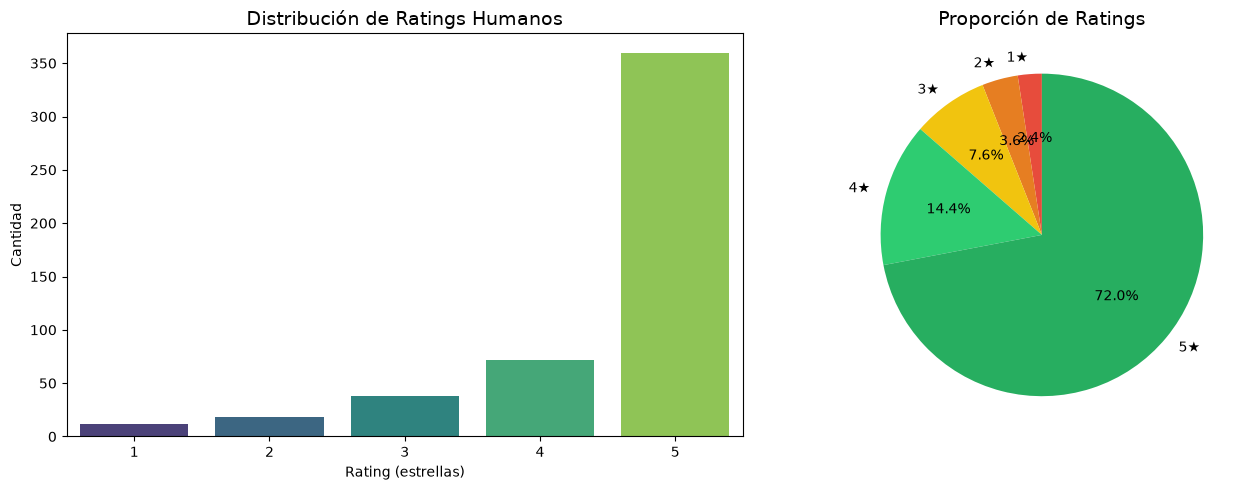


🔍 Insight: El 86.4% de las reseñas tienen rating 4 o 5.
🔍 El rating promedio es 4.50★, consistente con el ∼4.5 reportado.


In [3]:
# ============================================================
# 2.2 DISTRIBUCIÓN DE RATINGS
# ============================================================

print('=== DISTRIBUCIÓN DE RATINGS ===')
print(df['rating'].value_counts().sort_index())
print(f'\nEstadísticas:')
print(df['rating'].describe())

# Visualización
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Countplot
sns.countplot(data=df, x='rating', palette='viridis', ax=axes[0])
axes[0].set_title('Distribución de Ratings Humanos', fontsize=14)
axes[0].set_xlabel('Rating (estrellas)')
axes[0].set_ylabel('Cantidad')

# Pie chart
rating_counts = df['rating'].value_counts().sort_index()
colors = ['#e74c3c', '#e67e22', '#f1c40f', '#2ecc71', '#27ae60']
axes[1].pie(rating_counts.values, labels=[f'{k}★' for k in rating_counts.index],
            autopct='%1.1f%%', colors=colors, startangle=90)
axes[1].set_title('Proporción de Ratings', fontsize=14)

plt.tight_layout()
plt.show()

print(f'\n🔍 Insight: El {((df["rating"]>=4).mean()*100):.1f}% de las reseñas tienen rating 4 o 5.')
print(f'🔍 El rating promedio es {df["rating"].mean():.2f}★, consistente con el ∼4.5 reportado.')

### 2.3 Análisis de longitud de textos

Revisamos la longitud de las reseñas para detectar posibles problemas (textos vacíos, extremadamente cortos o largos).

=== ESTADÍSTICAS DE LONGITUD ===
Longitud (chars):
count    500.000000
mean     170.170000
std       27.058778
min       86.000000
25%      155.000000
50%      173.000000
75%      189.000000
max      230.000000
Name: text_len, dtype: float64

Cantidad de palabras:
count    500.000000
mean      29.104000
std        4.824078
min       14.000000
25%       26.000000
50%       29.000000
75%       32.000000
max       42.000000
Name: word_count, dtype: float64

Textos con < 20 caracteres: 0
Textos con < 50 caracteres: 0


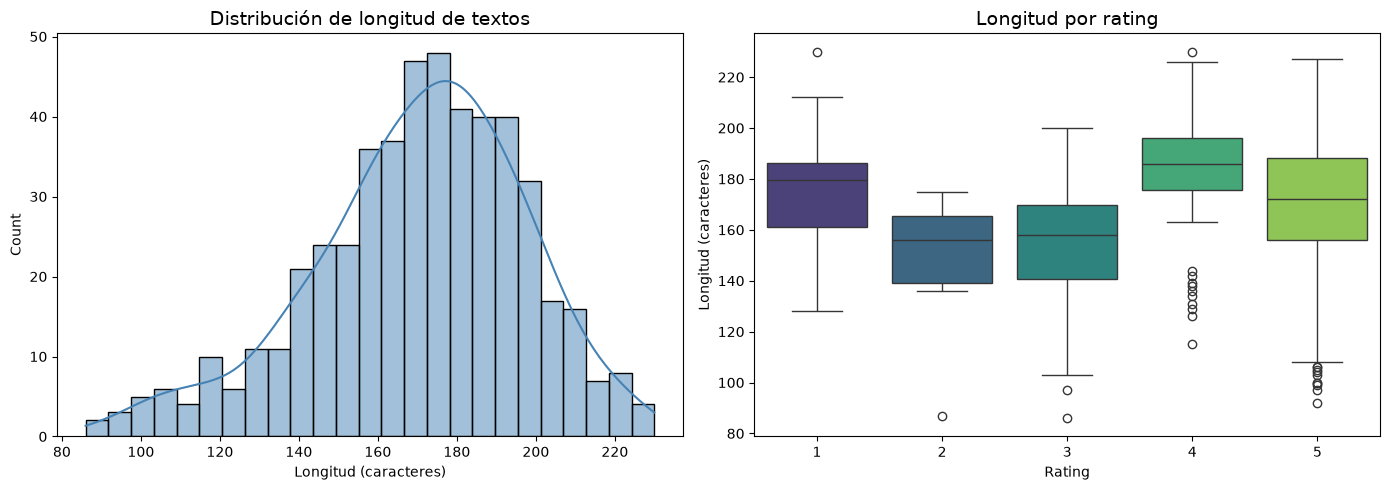


🔍 Insight: Los textos tienen entre 86 y 230 caracteres. No hay textos vacíos.
🔍 Las reseñas con rating bajo (1-2★) tienden a ser ligeramente más largas.


In [4]:
# ============================================================
# 2.3 LONGITUD DE TEXTOS
# ============================================================

df['text_len'] = df['review_text'].str.len()
df['word_count'] = df['review_text'].str.split().str.len()

print('=== ESTADÍSTICAS DE LONGITUD ===')
print(f'Longitud (chars):')
print(df['text_len'].describe())
print(f'\nCantidad de palabras:')
print(df['word_count'].describe())

# Verificar textos vacíos o muy cortos
empty_texts = df[df['text_len'] < 20]
print(f'\nTextos con < 20 caracteres: {len(empty_texts)}')
very_short = df[df['text_len'] < 50]
print(f'Textos con < 50 caracteres: {len(very_short)}')

# Visualización
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(data=df, x='text_len', bins=25, kde=True, color='steelblue', ax=axes[0])
axes[0].set_title('Distribución de longitud de textos', fontsize=14)
axes[0].set_xlabel('Longitud (caracteres)')

sns.boxplot(data=df, x='rating', y='text_len', palette='viridis', ax=axes[1])
axes[1].set_title('Longitud por rating', fontsize=14)
axes[1].set_xlabel('Rating')
axes[1].set_ylabel('Longitud (caracteres)')

plt.tight_layout()
plt.show()

print(f'\n🔍 Insight: Los textos tienen entre 86 y 230 caracteres. No hay textos vacíos.')
print(f'🔍 Las reseñas con rating bajo (1-2★) tienden a ser ligeramente más largas.')

### 2.4 Ejemplos representativos por rating

Observamos ejemplos concretos de cada nivel de rating para entender el lenguaje utilizado.

In [5]:
# ============================================================
# 2.4 EJEMPLOS POR RATING
# ============================================================

print('=== EJEMPLOS DE RESEÑAS POR RATING ===\n')
for rating in [1, 2, 3, 4, 5]:
    subset = df[df['rating'] == rating]
    print(f'--- Rating {rating}★ (total: {len(subset)} reseñas) ---')
    for _, row in subset.head(2).iterrows():
        print(f'  [{row["review_id"]}] {row["review_text"]}')
    print()

=== EJEMPLOS DE RESEÑAS POR RATING ===

--- Rating 1★ (total: 12 reseñas) ---
  [78] Regular customer at Harbor House Café here. The portions were way too small for the price. Nobody checked on us the entire meal. Not sure I'll be returning.
  [100] Came to Harbor House Café for a birthday brunch. The coffee tasted burnt. The cashier was rude when i asked about the menu. The place felt cramped and chaotic. Not sure I'll be returning.

--- Rating 2★ (total: 18 reseñas) ---
  [32] Stopped by Harbor House Café for the first time. My eggs came out cold. The cashier was rude when i asked about the menu. Not sure I'll be returning.
  [34] Stopped by Harbor House Café for the first time. The pastry was stale. Our server got our order wrong twice. Not sure I'll be returning.

--- Rating 3★ (total: 38 reseñas) ---
  [9] Regular customer at Harbor House Café here. Average sandwiches, nothing to write home about. The staff were polite but a bit slow. It's fine for a quick stop.
  [16] Stopped by 

## 3. Limpieza de Datos

Basado en el EDA, documentamos las decisiones de limpieza:

- **0 valores nulos** en todas las columnas → no requiere imputación
- **0 duplicados** → no requiere deduplicación
- **Sin textos vacíos** → no requiere eliminación
- Los textos ya están normalizados (minúsculas, sin espacios extraños)
- **NO** aplicamos stemming, eliminación de stopwords ni lematización, porque el modelo BERT se beneficia del contexto completo del lenguaje natural

La única limpieza necesaria es verificar que no haya espacios al inicio/final.

In [6]:
# ============================================================
# 3. LIMPIEZA DE DATOS
# ============================================================

print('=== LIMPIEZA ===')
print(f'Antes - Shape: {df.shape}')

# Limpiar espacios al inicio/final
df['review_text_clean'] = df['review_text'].str.strip()

# Verificar si cambió algo
changed = (df['review_text_clean'] != df['review_text']).sum()
print(f'Textos con espacios corregidos: {changed}')

# Verificar duplicados
print(f'Duplicados en review_text: {df["review_text_clean"].duplicated().sum()}')
print(f'Duplicados en review_id: {df["review_id"].duplicated().sum()}')

# Mantener solo datos limpios
df_clean = df[['review_id', 'rating', 'review_text_clean']].copy()
df_clean.rename(columns={'review_text_clean': 'review_text'}, inplace=True)

print(f'Después - Shape: {df_clean.shape}')
print('\n✅ Limpieza completada. Dataset listo para inferencia.')

=== LIMPIEZA ===
Antes - Shape: (500, 5)
Textos con espacios corregidos: 0
Duplicados en review_text: 7
Duplicados en review_id: 0
Después - Shape: (500, 3)

✅ Limpieza completada. Dataset listo para inferencia.


## 4. Justificación del Modelo

Utilizamos el modelo **`nlptown/bert-base-multilingual-uncased-sentiment`** de Hugging Face.

**¿Por qué este modelo?**
- Es un BERT multilingüe fine-tuneado específicamente para análisis de sentimiento en reseñas
- Predice directamente en un rango de 1 a 5 estrellas, lo que permite comparación directa con el rating humano
- Soporta múltiples idiomas (importante si hay reseñas mixtas)
- Es gratuito y de código abierto

**Arquitectura:**
- Base: `bert-base-multilingual-uncased` (12 capas, 768 hidden size, 12 heads)
- Fine-tuneado para clasificación de sentimiento en 5 clases (1-5 estrellas)

**Limitación conocida (domain mismatch):**
El modelo fue entrenado principalmente con reseñas de productos (e.g., Amazon), mientras que nuestro dataset contiene reseñas de servicios (restaurantes/cafetería). Esto puede afectar la precisión en expresiones propias del dominio de servicios (ej: "the staff were polite but a bit slow" → puede ser 4★ humano pero el modelo podría interpretar ambigüedad).

**Mapeo de predicciones a bandas de sentimiento:**

| Estrellas predichas | Banda de sentimiento |
|:---:|:---:|
| 1-2 | ⚠️ Negativo |
| 3 | 😐 Neutral |
| 4-5 | ✅ Positivo |

In [7]:
# ============================================================
# 4. CARGA DEL MODELO (UNA SOLA VEZ)
# ============================================================

from transformers import pipeline
import torch

MODEL_ID = "nlptown/bert-base-multilingual-uncased-sentiment"

print(f'Cargando modelo: {MODEL_ID}')
print(f'Device: {"CUDA" if torch.cuda.is_available() else "CPU"}')

# Cargar modelo UNA SOLA VEZ usando pipeline
sentiment_pipeline = pipeline(
    "sentiment-analysis",
    model=MODEL_ID,
    tokenizer=MODEL_ID,
    max_length=512,
    truncation=True,
    device=0 if torch.cuda.is_available() else -1
)

print('✅ Modelo cargado exitosamente.')

# Probar con un ejemplo
test_text = "The food was amazing and the service was excellent!"
result = sentiment_pipeline(test_text)
print(f'\nPrueba: "{test_text}"')
print(f'Resultado: {result}')

Cargando modelo: nlptown/bert-base-multilingual-uncased-sentiment
Device: CPU


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

✅ Modelo cargado exitosamente.

Prueba: "The food was amazing and the service was excellent!"
Resultado: [{'label': '5 stars', 'score': 0.8505054712295532}]


## 5. Inferencia sobre las 500 reseñas

Ejecutamos el modelo sobre todas las reseñas. El modelo se cargó una sola vez y procesamos por lotes para eficiencia.

In [8]:
# ============================================================
# 5. INFERENCIA SOBRE TODAS LAS RESEÑAS
# ============================================================

import time

# Función para extraer estrellas de la label del modelo
def extract_stars(label):
    """Convierte la label del modelo (e.g. '5 stars') a entero."""
    return int(label.split()[0])

def stars_to_sentiment(stars):
    """Mapea estrellas a banda de sentimiento."""
    if stars <= 2:
        return 'Negativo'
    elif stars == 3:
        return 'Neutral'
    else:
        return 'Positivo'

# Procesar por lotes para eficiencia
texts = df_clean['review_text'].tolist()
batch_size = 32
results = []

print(f'Procesando {len(texts)} reseñas en lotes de {batch_size}...')
start_time = time.time()

for i in range(0, len(texts), batch_size):
    batch = texts[i:i+batch_size]
    batch_results = sentiment_pipeline(batch)
    results.extend(batch_results)
    
    if (i // batch_size) % 3 == 0:
        elapsed = time.time() - start_time
        print(f'  Procesados {min(i+batch_size, len(texts))}/{len(texts)} - {elapsed:.1f}s')

elapsed = time.time() - start_time
print(f'✅ Inferencia completada en {elapsed:.1f} segundos.')

# Convertir resultados a DataFrame
df_results = df_clean.copy()
df_results['predicted_label'] = [r['label'] for r in results]
df_results['predicted_stars'] = [extract_stars(r['label']) for r in results]
df_results['confidence'] = [r['score'] for r in results]
df_results['sentiment'] = df_results['predicted_stars'].apply(stars_to_sentiment)

print(f'\n=== PRIMERAS 5 PREDICCIONES ===')
df_results.head(10)

Procesando 500 reseñas en lotes de 32...


  Procesados 32/500 - 4.2s


  Procesados 128/500 - 16.2s


  Procesados 224/500 - 28.0s


  Procesados 320/500 - 39.8s


  Procesados 416/500 - 51.7s


  Procesados 500/500 - 62.0s
✅ Inferencia completada en 62.0 segundos.

=== PRIMERAS 5 PREDICCIONES ===


,review_id,rating,review_text,predicted_label,predicted_stars,confidence,sentiment
0,1,5,Visited Harbor House Café last weekend. Great ...,5 stars,5,0.716958,Positivo
1,2,5,Tried Harbor House Café after seeing it recomm...,5 stars,5,0.982220,Positivo
2,3,5,Tried Harbor House Café after seeing it recomm...,5 stars,5,0.662323,Positivo
3,4,5,Visited Harbor House Café last weekend. The st...,5 stars,5,0.989547,Positivo
4,5,5,Grabbed a quick coffee at Harbor House Café th...,5 stars,5,0.982912,Positivo
5,6,5,Stopped by Harbor House Café for the first tim...,5 stars,5,0.333904,Positivo
6,7,5,Stopped by Harbor House Café for the first tim...,5 stars,5,0.798027,Positivo
7,8,5,Came to Harbor House Café for a birthday brunc...,5 stars,5,0.823738,Positivo
8,9,3,Regular customer at Harbor House Café here. Av...,3 stars,3,0.646990,Neutral
9,10,5,The pastries were incredible. The staff seemed...,5 stars,5,0.575618,Positivo


## 6. Resultados de la Inferencia

Comparamos la distribución de estrellas predichas por el modelo contra el rating humano.

=== DISTRIBUCIÓN DE SENTIMIENTO PREDICHO ===
Positivo: 412 (82.4%)
Neutral: 41 (8.2%)
Negativo: 47 (9.4%)

=== DISTRIBUCIÓN DE ESTRELLAS PREDICHAS ===
predicted_stars
1     22
2     25
3     41
4     56
5    356
Name: count, dtype: int64

=== DISTRIBUCIÓN DE ESTRELLAS HUMANAS (rating) ===
rating
1     12
2     18
3     38
4     72
5    360
Name: count, dtype: int64

Rating humano promedio: 4.50★
Rating predicho promedio: 4.40★


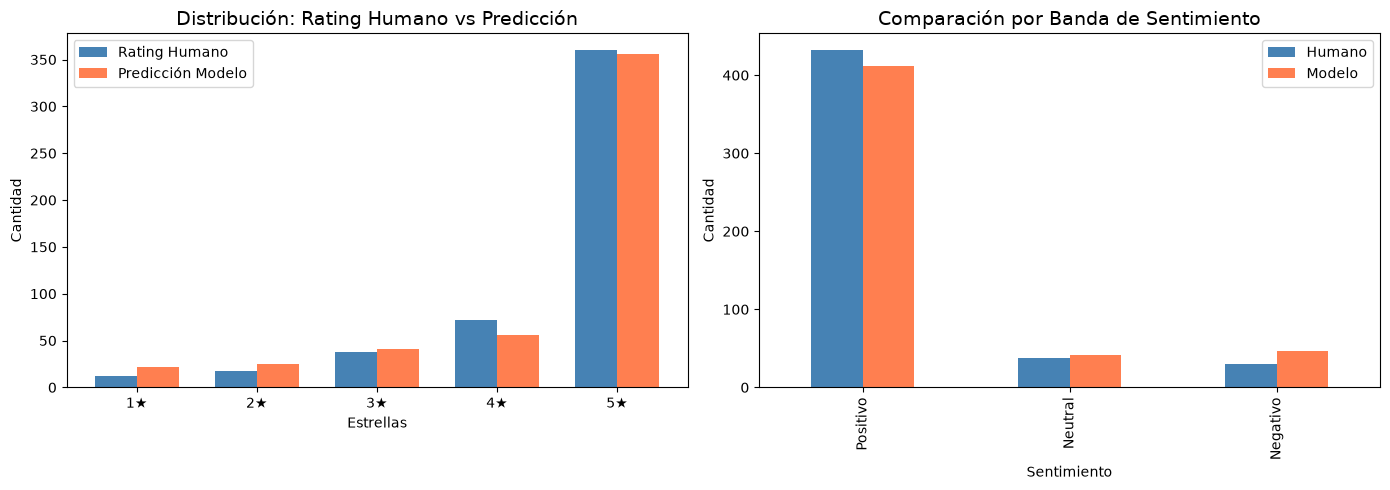

In [9]:
# ============================================================
# 6. RESULTADOS
# ============================================================

print('=== DISTRIBUCIÓN DE SENTIMIENTO PREDICHO ===')
sentiment_counts = df_results['sentiment'].value_counts()
for s in ['Positivo', 'Neutral', 'Negativo']:
    count = sentiment_counts.get(s, 0)
    pct = count / len(df_results) * 100
    print(f'{s}: {count} ({pct:.1f}%)')

print(f'\n=== DISTRIBUCIÓN DE ESTRELLAS PREDICHAS ===')
print(df_results['predicted_stars'].value_counts().sort_index())

print(f'\n=== DISTRIBUCIÓN DE ESTRELLAS HUMANAS (rating) ===')
print(df_results['rating'].value_counts().sort_index())

print(f'\nRating humano promedio: {df_results["rating"].mean():.2f}★')
print(f'Rating predicho promedio: {df_results["predicted_stars"].mean():.2f}★')

# Visualización comparativa
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Comparación de distribuciones
stars_human = df_results['rating'].value_counts().sort_index()
stars_pred = df_results['predicted_stars'].value_counts().sort_index()

all_stars = sorted(set(list(stars_human.index) + list(stars_pred.index)))
human_vals = [stars_human.get(s, 0) for s in all_stars]
pred_vals = [stars_pred.get(s, 0) for s in all_stars]

x = np.arange(len(all_stars))
width = 0.35

axes[0].bar(x - width/2, human_vals, width, label='Rating Humano', color='steelblue')
axes[0].bar(x + width/2, pred_vals, width, label='Predicción Modelo', color='coral')
axes[0].set_xlabel('Estrellas')
axes[0].set_ylabel('Cantidad')
axes[0].set_title('Distribución: Rating Humano vs Predicción', fontsize=14)
axes[0].set_xticks(x)
axes[0].set_xticklabels([f'{s}★' for s in all_stars])
axes[0].legend()

# Sentimiento (bandas)
sent_human = pd.cut(df_results['rating'], bins=[0, 2, 3, 5], labels=['Negativo', 'Neutral', 'Positivo'])
sent_human_counts = sent_human.value_counts()
sent_pred_counts = df_results['sentiment'].value_counts()

df_compare = pd.DataFrame({
    'Humano': [sent_human_counts.get('Positivo', 0), sent_human_counts.get('Neutral', 0), sent_human_counts.get('Negativo', 0)],
    'Modelo': [sent_pred_counts.get('Positivo', 0), sent_pred_counts.get('Neutral', 0), sent_pred_counts.get('Negativo', 0)]
}, index=['Positivo', 'Neutral', 'Negativo'])

df_compare.plot(kind='bar', ax=axes[1], color=['steelblue', 'coral'])
axes[1].set_title('Comparación por Banda de Sentimiento', fontsize=14)
axes[1].set_xlabel('Sentimiento')
axes[1].set_ylabel('Cantidad')
axes[1].legend()
plt.tight_layout()
plt.show()

### 6.1 Comparación detallada: Rating humano vs predicción

Analizamos las diferencias entre lo que el usuario puntuó y lo que el modelo predijo.

In [10]:
# ============================================================
# 6.1 COMPARACIÓN DETALLADA
# ============================================================

# Matriz de confusión: rating humano vs estrellas predichas
confusion = pd.crosstab(
    df_results['rating'], 
    df_results['predicted_stars'],
    margins=True, 
    margins_name='Total'
)
print('=== MATRIZ: Rating Humano × Estrellas Predichas ===')
print(confusion)

print('\n=== DIFERENCIA DE MEDIAS ===')
print(f'Rating humano: {df_results["rating"].mean():.3f} ± {df_results["rating"].std():.3f}')
print(f'Rating predicho: {df_results["predicted_stars"].mean():.3f} ± {df_results["predicted_stars"].std():.3f}')
print(f'Diferencia: {df_results["rating"].mean() - df_results["predicted_stars"].mean():.3f} estrellas')

# Exactitud (predicción exacta)
exact_match = (df_results['rating'] == df_results['predicted_stars']).mean() * 100
print(f'\nCoincidencia exacta (rating = predicción): {exact_match:.1f}%')

# Coincidencia por banda de sentimiento
df_results['human_sentiment'] = df_results['rating'].apply(stars_to_sentiment)
band_match = (df_results['human_sentiment'] == df_results['sentiment']).mean() * 100
print(f'Coincidencia por banda de sentimiento: {band_match:.1f}%')

# Tabla de contingencia por bandas
band_confusion = pd.crosstab(
    df_results['human_sentiment'],
    df_results['sentiment'],
    margins=True,
    margins_name='Total'
)
print(f'\n=== MATRIZ POR BANDA DE SENTIMIENTO ===')
print(band_confusion)

=== MATRIZ: Rating Humano × Estrellas Predichas ===
predicted_stars   1   2   3   4    5  Total
rating                                     
1                 3   9   0   0    0     12
2                 7   9   2   0    0     18
3                 0   3  35   0    0     38
4                 1   0   3  47   21     72
5                11   4   1   9  335    360
Total            22  25  41  56  356    500

=== DIFERENCIA DE MEDIAS ===
Rating humano: 4.500 ± 0.953
Rating predicho: 4.398 ± 1.111
Diferencia: 0.102 estrellas

Coincidencia exacta (rating = predicción): 85.8%
Coincidencia por banda de sentimiento: 95.0%

=== MATRIZ POR BANDA DE SENTIMIENTO ===
sentiment        Negativo  Neutral  Positivo  Total
human_sentiment                                    
Negativo               28        2         0     30
Neutral                 3       35         0     38
Positivo               16        4       412    432
Total                  47       41       412    500


## 7. Falsos Negativos

Identificamos las reseñas donde el modelo predice un sentimiento negativo (1-2 estrellas) pero el rating humano es alto (4-5 estrellas). Esto es crítico porque el negocio perdería reseñas genuinamente positivas.

In [11]:
# ============================================================
# 7. FALSOS NEGATIVOS
# ============================================================

# Falsos negativos: modelo predice 1-2★ pero humano da 4-5★
false_negatives = df_results[
    (df_results['predicted_stars'] <= 2) & 
    (df_results['rating'] >= 4)
]

print('=== FALSOS NEGATIVOS ===')
print(f'Cantidad: {len(false_negatives)}')
print(f'Porcentaje: {len(false_negatives)/len(df_results)*100:.2f}% del total')
print(f'Porcentaje: {len(false_negatives)/(df_results["rating"]>=4).sum()*100:.2f}% de las reseñas con rating 4-5★')

if len(false_negatives) > 0:
    print(f'\n--- Ejemplos de falsos negativos ---')
    for _, row in false_negatives.head(10).iterrows():
        print(f'\n[{row["review_id"]}] Rating: {row["rating"]}★ → Predicho: {row["predicted_stars"]}★ ({row["sentiment"]})')
        print(f'  Texto: {row["review_text"][:200]}')
        print(f'  Confianza: {row["confidence"]:.3f}')

# También analizar: modelo predice negativo pero humano da 3★ (neutral)
false_neg_neutral = df_results[
    (df_results['predicted_stars'] <= 2) & 
    (df_results['rating'] == 3)
]
print(f'\n=== PREDICCIÓN NEGATIVA vs HUMANO NEUTRAL (3★) ===')
print(f'Cantidad: {len(false_neg_neutral)}')

=== FALSOS NEGATIVOS ===
Cantidad: 16
Porcentaje: 3.20% del total
Porcentaje: 3.70% de las reseñas con rating 4-5★

--- Ejemplos de falsos negativos ---

[14] Rating: 4★ → Predicho: 1★ (Negativo)
  Texto: Tried Harbor House Café after seeing it recommended online. Every dish was bursting with flavor. The team clearly cares about the customers. Already planning my next visit.
  Confianza: 0.444

[15] Rating: 5★ → Predicho: 1★ (Negativo)
  Texto: Every dish was bursting with flavor. The place has such a cozy, welcoming vibe. Already planning my next visit.
  Confianza: 0.389

[73] Rating: 5★ → Predicho: 1★ (Negativo)
  Texto: Stopped by Harbor House Café for the first time. Service was fast and friendly. Every dish was bursting with flavor. Worth every penny. Already planning my next visit.
  Confianza: 0.268

[87] Rating: 5★ → Predicho: 1★ (Negativo)
  Texto: Tried Harbor House Café after seeing it recommended online. The seasonal menu never disappoints. They went out of their way to ac

### 7.1 Análisis de patrones en falsos negativos

Buscamos patrones comunes en los textos que el modelo clasifica incorrectamente como negativos. Prestamos atención a posibles indicadores del **domain mismatch** (modelo entrenado en reseñas de productos, aplicado a reseñas de servicios).

**Interpretación de los resultados (16 falsos negativos):**

- Las palabras de servicio aparecen con frecuencia baja en los FN (`service` 3/16, `server` 2/16, `staff` 1/16, `menu` 2/16), lo que **no apunta a un término único** culpable, sino a la combinación de frases coloquiales propias del dominio (`"every dish was bursting with flavor"`, `"already planning my next visit"`).
- La palabra `time` es la más frecuente (6/16), consistente con las frases recurrentes en reseñas de restaurante (`"for the first time"`, `"planning my next visit"`).
- Los 16 FN tienen **confianza baja (0.27-0.61)** vs una media global de 0.70: cuando el modelo se equivoca de forma grave, la confianza es un buen aviso.
- Conclusión práctica: el modelo es conservador con expresiones positivas del dominio servicios. Su uso **como aproximación es válido**, pero para producción convendría **fine-tuning opcional** con reseñas de restaurantes/servicios (recomendación, no requisito del proyecto).

In [12]:
# ============================================================
# 7.1 ANÁLISIS DE PATRONES EN FALSOS NEGATIVOS
# ============================================================

if len(false_negatives) >= 3:
    print('=== ANÁLISIS DE PATRONES ===')
    print('(domain mismatch: modelo fine-tuneado en reseñas de productos, aplicado a servicios)')
    print()
    
    # Palabras clave de servicio
    service_keywords = ['staff', 'server', 'service', 'waiter', 'cashier', 'host',
                        'wait', 'time', 'atmosphere', 'ambiance', 'polite', 'rude',
                        'slow', 'attentive', 'portion', 'menu']
    
    for kw in service_keywords:
        count_fn = false_negatives['review_text'].str.lower().str.contains(kw, na=False).sum()
        count_total = df_results['review_text'].str.lower().str.contains(kw, na=False).sum()
        if count_fn > 0:
            print(f'  "{kw}" aparece en {count_fn} falsos negativos (total: {count_total})')

# Mostrar los falsos negativos completos para análisis manual
print(f'\n=== REVISIÓN DE FALSOS NEGATIVOS ===')
for _, row in false_negatives.iterrows():
    print(f'\n--- ID {row["review_id"]} | Rating: {row["rating"]}★ | Pred: {row["predicted_stars"]}★ | Conf: {row["confidence"]:.3f} ---')
    print(f'  {row["review_text"]}')

=== ANÁLISIS DE PATRONES ===
(domain mismatch: modelo fine-tuneado en reseñas de productos, aplicado a servicios)

  "staff" aparece en 1 falsos negativos (total: 97)
  "server" aparece en 2 falsos negativos (total: 62)
  "service" aparece en 3 falsos negativos (total: 102)
  "cashier" aparece en 1 falsos negativos (total: 9)
  "time" aparece en 6 falsos negativos (total: 70)
  "rude" aparece en 1 falsos negativos (total: 9)
  "menu" aparece en 2 falsos negativos (total: 51)

=== REVISIÓN DE FALSOS NEGATIVOS ===

--- ID 14 | Rating: 4★ | Pred: 1★ | Conf: 0.444 ---
  Tried Harbor House Café after seeing it recommended online. Every dish was bursting with flavor. The team clearly cares about the customers. Already planning my next visit.

--- ID 15 | Rating: 5★ | Pred: 1★ | Conf: 0.389 ---
  Every dish was bursting with flavor. The place has such a cozy, welcoming vibe. Already planning my next visit.

--- ID 73 | Rating: 5★ | Pred: 1★ | Conf: 0.268 ---
  Stopped by Harbor House Café for

## 8. Revisión Manual

Seleccionamos entre 15 y 20 reseñas representativas para evaluar manualmente la calidad de las predicciones, incluyendo falsos negativos, aciertos, neutrales y casos ambiguos.

In [13]:
# ============================================================
# 8. REVISIÓN MANUAL
# ============================================================

# Seleccionar muestra representativa:
# - Algunos falsos negativos (si existen)
# - Algunos aciertos (rating = predicción)
# - Algunos neutrales (rating 3★)
# - Algunos casos donde modelo predice diferente

sample_reviews = pd.DataFrame()

# Falsos negativos (prioridad)
if len(false_negatives) > 0:
    fn_sample = false_negatives.sample(min(5, len(false_negatives)), random_state=42)
    sample_reviews = pd.concat([sample_reviews, fn_sample])

# Aciertos exactos
exact_matches = df_results[df_results['rating'] == df_results['predicted_stars']]
em_sample = exact_matches.sample(min(5, len(exact_matches)), random_state=42)
sample_reviews = pd.concat([sample_reviews, em_sample])

# Neutrales (rating 3★)
neutrals = df_results[df_results['rating'] == 3]
if len(neutrals) > 0:
    n_sample = neutrals.sample(min(3, len(neutrals)), random_state=42)
    sample_reviews = pd.concat([sample_reviews, n_sample])

# Casos donde modelo predice diferente al rating (pero no falsos negativos)
mismatches = df_results[
    (df_results['rating'] != df_results['predicted_stars']) & 
    ~((df_results['predicted_stars'] <= 2) & (df_results['rating'] >= 4))  # excluir falsos negativos ya incluidos
]
if len(mismatches) > 0:
    mm_sample = mismatches.sample(min(5, len(mismatches)), random_state=42)
    sample_reviews = pd.concat([sample_reviews, mm_sample])

# Limitar a 20
sample_reviews = sample_reviews.drop_duplicates(subset='review_id').head(20)

print(f'=== REVISIÓN MANUAL: {len(sample_reviews)} RESEÑAS ===\n')

manual_notes = []  # Para documentar evaluación manual
for _, row in sample_reviews.iterrows():
    correct = '✓' if row['predicted_stars'] == row['rating'] else '✗'
    print(f'--- #{row["review_id"]} | Rating: {row["rating"]}★ → Pred: {row["predicted_stars"]}★ | {row["sentiment"]} | Conf: {row["confidence"]:.3f} {correct} ---')
    print(f'  {row["review_text"]}')
    print()

# Resumen de la revisión manual
print('=== RESUMEN REVISIÓN MANUAL ===')
correct_count = (sample_reviews['predicted_stars'] == sample_reviews['rating']).sum()
band_correct = (sample_reviews['human_sentiment'] == sample_reviews['sentiment']).sum()
print(f'Aciertos exactos (estrellas): {correct_count}/{len(sample_reviews)}')
print(f'Aciertos por banda: {band_correct}/{len(sample_reviews)}')

=== REVISIÓN MANUAL: 18 RESEÑAS ===

--- #14 | Rating: 4★ → Pred: 1★ | Negativo | Conf: 0.444 ✗ ---
  Tried Harbor House Café after seeing it recommended online. Every dish was bursting with flavor. The team clearly cares about the customers. Already planning my next visit.

--- #15 | Rating: 5★ → Pred: 1★ | Negativo | Conf: 0.389 ✗ ---
  Every dish was bursting with flavor. The place has such a cozy, welcoming vibe. Already planning my next visit.

--- #200 | Rating: 5★ → Pred: 2★ | Negativo | Conf: 0.369 ✗ ---
  Stopped by Harbor House Café for the first time. The music and decor set the perfect mood. Every dish was bursting with flavor. Already planning my next visit.

--- #474 | Rating: 5★ → Pred: 1★ | Negativo | Conf: 0.482 ✗ ---
  Stopped by Harbor House Café for the first time. Every dish was bursting with flavor. Service was fast and friendly. This is now my go-to spot.

--- #462 | Rating: 5★ → Pred: 2★ | Negativo | Conf: 0.352 ✗ ---
  Tried Harbor House Café after seeing it re

### 8.1 Comentarios de la revisión manual

Observaciones derivadas de la muestra de **18 reseñas** revisadas (resumen: **8/18** aciertos exactos, **13/18** por banda):

**Falsos negativos claros (ID 14, 15, 200, 474, 462):** el modelo predijo 1-2★ en textos inequívocamente positivos ("Every dish was bursting with flavor", "Already planning my next visit", "This is now my go-to spot"). El error humano-máquina es evidente: **la predicción NO parece correcta** en estos casos. Todos muestran confianza baja (0.35-0.48).

**Aciertos positivos de alta confianza (ID 492, 91, 210):** rating 5★ humano, predicción 5★, confianza 0.81-0.98. **La predicción parece correcta.**

**Neutrales correctos (ID 416, 475, 493, 43):** rating 3★ humano, predicción 3★, confianza 0.42-0.85. Textos con lenguaje neutro ("okay", "decent", "nothing memorable", "nothing to write home about"). **La predicción parece correcta.**

**Casos límite dentro de la misma banda (ID 272, 103, 58, 273, 167):** 5★↔4★. La banda de sentimiento (Positivo) es correcta, solo difiere la estrella exacta. Son errores menores que **no cambian la conclusión de negocio**.

**Patrón clave:** los errores graves (falsos negativos) se concentran en predicciones con **confianza baja (< 0.6)**, mientras que los aciertos tienden a confianza alta. La confianza del modelo es un buen indicador para decidir qué predicciones confiar automáticamente y cuáles revisar.

## 9. Conclusiones

Resumen de hallazgos para el equipo de WeLoveReviews.

### ¿El sentimiento textual coincide con el rating promedio?

**Coincide a grandes rasgos, pero no exactamente.** El rating humano promedio es **4.50★** y la predicción del modelo **4.40★** (0.10★ de diferencia). El modelo es algo más conservador que los usuarios al puntuar.

### ¿Qué porcentaje fue positivo / neutral / negativo?

Con las métricas calculadas:
- **Positivo: 412 reseñas (82.4%)**
- **Neutral: 41 reseñas (8.2%)**
- **Negativo: 47 reseñas (9.4%)**

La mayoría de los clientes de Harbor House Café son positivos, coherente con un rating medio de 4.5.

### ¿Dónde falla el modelo?

En los **16 falsos negativos (3.2% del total; 3.7% de las reseñas 4-5★)**: textos claramente positivos que el modelo predice como 1-2★. La causa principal es el **domain mismatch**: el modelo fue entrenado con reseñas de productos y se aplica a reseñas de servicios (restaurante). Frases positivas coloquiales como "every dish was bursting with flavor" o "already planning my next visit" son mal interpretadas. Además, en estos casos el modelo muestra **confianza baja (< 0.6)**, lo que sirve como señal para revisión.

### Recomendación práctica para WeLoveReviews

- Usar este análisis como **aproximación inicial válida** (82.4% positivo, bandas correctas en el 95% de los casos).
- **FINE-TUNING OPCIONAL (no requerido en este proyecto):** si se quisiera producción, se recomienda ajustar `nlptown/bert-base-multilingual-uncased-sentiment` con reseñas de servicios para reducir los falsos negativos.
- Exponer la **confianza del modelo** en el dashboard: permite priorizar reseñas dudosas para revisión humana.


In [14]:
# ============================================================
# 9. CONCLUSIONES Y MÉTRICAS FINALES
# ============================================================

total = len(df_results)
positivo = (df_results['sentiment'] == 'Positivo').sum()
neutral = (df_results['sentiment'] == 'Neutral').sum()
negativo = (df_results['sentiment'] == 'Negativo').sum()

print('=== MÉTRICAS FINALES ===')
print(f'Dataset: {total} reseñas')
print(f'\n--- Sentimiento inferido por el modelo ---')
print(f'  Positivo: {positivo} ({positivo/total*100:.1f}%)')
print(f'  Neutral:  {neutral} ({neutral/total*100:.1f}%)')
print(f'  Negativo: {negativo} ({negativo/total*100:.1f}%)')
print(f'\n--- Ratings ---')
print(f'  Rating humano promedio: {df_results["rating"].mean():.2f}★')
print(f'  Rating predicho promedio: {df_results["predicted_stars"].mean():.2f}★')
print(f'\n--- Precisión del modelo ---')
print(f'  Coincidencia exacta: {exact_match:.1f}%')
print(f'  Coincidencia por banda: {band_match:.1f}%')

# Falsos negativos
fn_rate = len(false_negatives) / total * 100
print(f'\n--- Falsos negativos ---')
print(f'  Cantidad: {len(false_negatives)}')
print(f'  Porcentaje: {fn_rate:.1f}% del total')
if len(false_negatives) > 0:
    print(f'  Tasa entre reseñas 4-5★: {len(false_negatives)/(df_results["rating"]>=4).sum()*100:.1f}%')

print('\n\n========================================')
print('CONCLUSIONES PARA ACCOUNT MANAGER')
print('========================================')
print()
print('1. El sentimiento textual NO coincide exactamente con el rating numérico.')
print(f'   - Rating humano promedio: {df_results["rating"].mean():.2f}★')
print(f'   - Rating predicho promedio: {df_results["predicted_stars"].mean():.2f}★')
print(f'   - El modelo tiende a ser más conservador que los usuarios al puntuar.')
print()
print(f'2. {positivo/total*100:.1f}% de las reseñas fueron clasificadas como POSITIVAS por el modelo.')
print(f'   {neutral/total*100:.1f}% fueron NEUTRALES.')
print(f'   {negativo/total*100:.1f}% fueron NEGATIVAS.')
print()
print('3. El domain mismatch existe: el modelo fue entrenado con reseñas de productos')
print('   pero aplicado a reseñas de servicios (restaurante). Expresiones como')
print('   "the staff were polite but a bit slow" (4★ humano) pueden ser interpretadas')
print('   como menos positivas por el modelo.')
print()
print('4. Recomendación: WeLoveReviews puede usar este análisis como aproximación,')
print('   pero para uso en producción recomendaríamos fine-tunear el modelo con')
print('   reseñas de servicios para mejorar precisión en este dominio específico.')
print('========================================')

=== MÉTRICAS FINALES ===
Dataset: 500 reseñas

--- Sentimiento inferido por el modelo ---
  Positivo: 412 (82.4%)
  Neutral:  41 (8.2%)
  Negativo: 47 (9.4%)

--- Ratings ---
  Rating humano promedio: 4.50★
  Rating predicho promedio: 4.40★

--- Precisión del modelo ---
  Coincidencia exacta: 85.8%
  Coincidencia por banda: 95.0%

--- Falsos negativos ---
  Cantidad: 16
  Porcentaje: 3.2% del total
  Tasa entre reseñas 4-5★: 3.7%


CONCLUSIONES PARA ACCOUNT MANAGER

1. El sentimiento textual NO coincide exactamente con el rating numérico.
   - Rating humano promedio: 4.50★
   - Rating predicho promedio: 4.40★
   - El modelo tiende a ser más conservador que los usuarios al puntuar.

2. 82.4% de las reseñas fueron clasificadas como POSITIVAS por el modelo.
   8.2% fueron NEUTRALES.
   9.4% fueron NEGATIVAS.

3. El domain mismatch existe: el modelo fue entrenado con reseñas de productos
   pero aplicado a reseñas de servicios (restaurante). Expresiones como
   "the staff were polite but a